<a href="https://colab.research.google.com/github/kolpmm/-_-/blob/main/ex02_transform_tiefighter_%EB%B0%B0%ED%8F%AC_ipynb%EC%9D%98_%EC%82%AC%EB%B3%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 라이브러리 선언

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

### 축 그리기 및 사각형 그리기

In [3]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [4]:
def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4])
  ax.add_patch(my_polygon)

In [5]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_rectangle(ax, p1, p2, p3, p4)

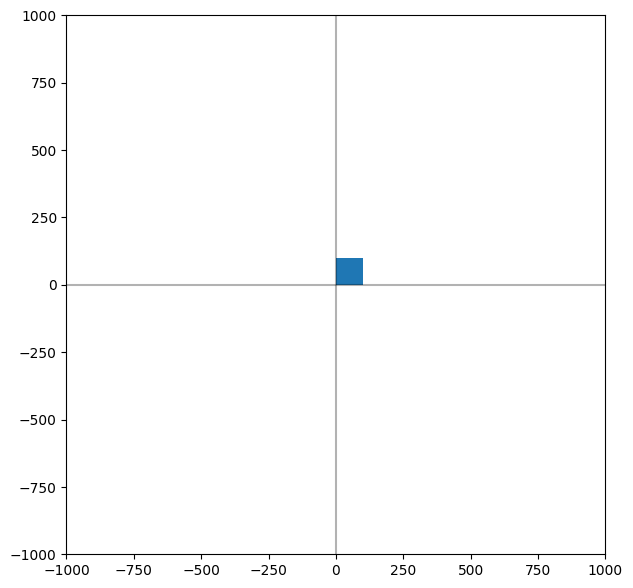

In [6]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()

### 본론
#### 1. 변환 구현
* translate(p, dx, dy)
* rotate(p, theta)  
* scale(p, sx, sy)  
* shear_x(p, sx)  
* shear_y(p, sy)  
* reflect_x(p)  
* reflect_y(p)   
* reflect_0(p)
* reflect_xy(p)

In [7]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [8]:
def rotate(p, theta):

  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 회전 변환 행렬 생성
  m = np.array([[np.cos(theta), -np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q


In [9]:
def scale(p, sx, sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 확대,축소 변환 행렬 생성
  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [10]:
def reflect_x(p):
   # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x 반사 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [11]:
def reflect_y(p):
   # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y 반사 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [12]:
def reflect_0(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 원점 반전 변환 행렬 생성
  m = np.array([[-1.0, 0.0, 0.0], [0.0, -1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [13]:
def reflect_xy(p):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y=x 반전 변환 행렬 생성
  m = np.array([[0.0, 1.0, 0.0], [1.0, 0.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [14]:
def shear_x(p, sx):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. x 기울이기 변환 행렬 생성
  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [15]:
def shear_y(p,sy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. y 기울이기 변환 행렬 생성
  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0, 0.0], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

#### 2. 파트 그리기
* draw_cockpit(p1, p2, p3, p4)    # 중앙 조종석
* draw_left_arm(p1, p2, p3, p4)   # 왼쪽 날개축
* draw_left_wing(p1, p2, p3, p4)  # 왼쪽 날개
* draw_right_arm(p1, p2, p3, p4)  # 오른쪽 날개축
* draw_right_wing(p1, p2, p3, p4) # 오른쪽 날개

In [16]:
def draw_cockpit(ax, p1, p2, p3, p4):  # 중앙 조종석
  # 1. 사각형을 원점으로 이동 변환: T(-LEN/2, -LEN/2)
  # q = T(-LEN/2, -LEN/2)p
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)


  # 2. 크기 변환: S(5, 5)
  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  # 3. 회전 변환: R(pi/4)
  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)


  # 4. polygon 그리기
  draw_rectangle(ax, q1, q2, q3, q4)

In [70]:
def draw_left_arm(ax, p1, p2, p3, p4):
    # 1. 사각형 중심을 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 크기 변환: x축으로 5.5배 길게, y축 두께는 0.5배로 납작하게
    q1 = scale(q1, 5.5, 0.7)
    q2 = scale(q2, 5.5, 0.7)
    q3 = scale(q3, 5.5, 0.7)
    q4 = scale(q4, 5.5, 0.7)

    # 3. y축 기울기(shear_y) 또는 회전(rotate)
    # 날개 축이 왼쪽 끝(-750, 0)에서 조종석 상단(-200, 100)으로 비스듬히 올라가도록 회전
    angle = -0.15  # 약 -8.5도 회전 (위쪽 가지)
    q1 = rotate(q1, angle)
    q2 = rotate(q2, angle)
    q3 = rotate(q3, angle)
    q4 = rotate(q4, angle)

    # 4. 왼쪽 날개 연결 위치로 이동
    # x축: 조종석과 날개 사이(480 정도), y축: (50 정도)
    dx, dy = 480, 50
    q1 = translate(q1, dx, dy)
    q2 = translate(q2, dx, dy)
    q3 = translate(q3, dx, dy)
    q4 = translate(q4, dx, dy)

    # 5. 위쪽 날개 축 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

    # 6. x축 대칭(reflect_x)으로 아래쪽 날개 축 생성
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    # 7. 아래쪽 날개 축 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

In [67]:
def draw_left_wing(ax, p1, p2, p3, p4):
    # 1. 사각형 중심을 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 크기 변환: x축 두께는 1배(또는 0.8배), y축 길이는 5.5배로 세로로 길게 설정
    q1 = scale(q1, 1.5, 5.5)
    q2 = scale(q2, 1.5, 5.5)
    q3 = scale(q3, 1.5, 5.5)
    q4 = scale(q4, 1.5, 5.5)

    # 3. y축 기울이기 변환 (날개의 위/아래 뾰족한 경사면 구현)
    # y축 방향으로 밀어서 윗면과 아랫면이 비스듬하게 깎인 평행사변형 형태로 변환
    sh = 1.0  # 기울기 계수
    #q1 = shear_y(q1, sh)
    #q2 = shear_y(q2, sh)
    q3 = shear_y(q3, sh)
    q4 = shear_y(q4, sh)

    # 4. 왼쪽 날개 위치로 이동
    # 날개 축 끝단(x ≈ 800)과 위쪽 날개 높이(y ≈ 280)에 맞게 이동
    dx, dy = 800, 280
    q1 = translate(q1, dx, dy)
    q2 = translate(q2, dx, dy)
    q3 = translate(q3, dx, dy)
    q4 = translate(q4, dx, dy)

    # 5. 위쪽 날개 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

    # 6. x축 반사 (y=0 기준으로 대칭 이동하여 아래쪽 날개 생성)
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    # 7. 아래쪽 날개 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

In [74]:
def draw_right_arm(ax, p1, p2, p3, p4):
    # 1. 사각형 중심을 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 크기 변환: x축으로 5.5배 길게, y축 두께는 0.5배로 납작하게
    q1 = scale(q1, 5.5, 0.7)
    q2 = scale(q2, 5.5, 0.7)
    q3 = scale(q3, 5.5, 0.7)
    q4 = scale(q4, 5.5, 0.7)

    # 3. y축 기울기(shear_y) 또는 회전(rotate)
    # 날개 축이 왼쪽 끝(-750, 0)에서 조종석 상단(-200, 100)으로 비스듬히 올라가도록 회전
    angle = 0.15  # 약 8.5도 회전 (위쪽 가지)
    q1 = rotate(q1, angle)
    q2 = rotate(q2, angle)
    q3 = rotate(q3, angle)
    q4 = rotate(q4, angle)

    # 4. 왼쪽 날개 연결 위치로 이동
    # x축: 조종석과 날개 사이(480 정도), y축: (50 정도)
    dx, dy = -480, 50
    q1 = translate(q1, dx, dy)
    q2 = translate(q2, dx, dy)
    q3 = translate(q3, dx, dy)
    q4 = translate(q4, dx, dy)

    # 5. 위쪽 날개 축 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

    # 6. x축 대칭(reflect_x)으로 아래쪽 날개 축 생성
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    # 7. 아래쪽 날개 축 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

In [73]:
def draw_right_wing(ax, p1, p2, p3, p4):
    # 1. 사각형 중심을 원점으로 이동
    q1 = translate(p1, -LEN/2, -LEN/2)
    q2 = translate(p2, -LEN/2, -LEN/2)
    q3 = translate(p3, -LEN/2, -LEN/2)
    q4 = translate(p4, -LEN/2, -LEN/2)

    # 2. 크기 변환: x축 두께는 1배(또는 0.8배), y축 길이는 5.5배로 세로로 길게 설정
    q1 = scale(q1, 1.5, 5.5)
    q2 = scale(q2, 1.5, 5.5)
    q3 = scale(q3, 1.5, 5.5)
    q4 = scale(q4, 1.5, 5.5)

    # 3. y축 기울이기 변환 (날개의 위/아래 뾰족한 경사면 구현)
    # y축 방향으로 밀어서 윗면과 아랫면이 비스듬하게 깎인 평행사변형 형태로 변환
    sh = -1.0  # 기울기 계수
    #q1 = shear_y(q1, sh)
    #q2 = shear_y(q2, sh)
    q3 = shear_y(q3, sh)
    q4 = shear_y(q4, sh)

    # 4. 왼쪽 날개 위치로 이동
    # 날개 축 끝단(x ≈ 800)과 위쪽 날개 높이(y ≈ 280)에 맞게 이동
    dx, dy = -800, 280
    q1 = translate(q1, dx, dy)
    q2 = translate(q2, dx, dy)
    q3 = translate(q3, dx, dy)
    q4 = translate(q4, dx, dy)

    # 5. 위쪽 날개 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

    # 6. x축 반사 (y=0 기준으로 대칭 이동하여 아래쪽 날개 생성)
    q1 = reflect_x(q1)
    q2 = reflect_x(q2)
    q3 = reflect_x(q3)
    q4 = reflect_x(q4)

    # 7. 아래쪽 날개 그리기
    draw_rectangle(ax, q1, q2, q3, q4)

In [75]:
# 2. tiefigher 그리기
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  # 1. 중앙 조종석 그리기
  draw_cockpit(ax, p1, p2, p3, p4)
  draw_left_arm(ax, p1, p2, p3, p4)
  draw_left_wing(ax, p1, p2, p3, p4)
  draw_right_arm(ax, p1, p2, p3, p4)
  draw_right_wing(ax, p1, p2, p3, p4)

### 3. main

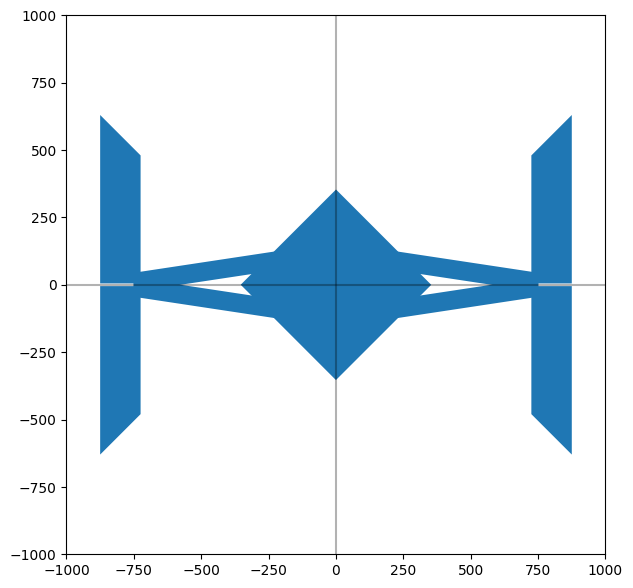

In [76]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()